In [12]:
# !pip install segmentation-models-pytorch

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

import segmentation_models_pytorch as smp
from tqdm import tqdm
from sklearn.model_selection import train_test_split

In [13]:
train_image_dir = r"/Users/kmsreenidhi/ACV Case Study/archive (2)/ISIC2018_Task1-2_Training_Input"
mask_dir        = r"/Users/kmsreenidhi/ACV Case Study/archive (2)/ISIC2018_Task1_Training_GroundTruth"

print("Train images exist:", os.path.exists(train_image_dir))
print("Masks exist:", os.path.exists(mask_dir))

Train images exist: True
Masks exist: True


In [14]:
all_images = []
all_masks = os.listdir(mask_dir)

# Create a set of valid mask base names
mask_basenames = set([m.replace("_segmentation.png", "") for m in all_masks])

# Keep only images that have masks
for img in os.listdir(train_image_dir):
    base_name = os.path.splitext(img)[0]
    if base_name in mask_basenames:
        all_images.append(img)

print("Total valid image-mask pairs:", len(all_images))

print("Total Training Images:", len(all_images))
print("Total Masks:", len(os.listdir(mask_dir)))

Total valid image-mask pairs: 2594
Total Training Images: 2594
Total Masks: 2596


In [15]:
train_images, val_images = train_test_split(
    all_images,
    test_size=0.2,
    random_state=42
)

print("Train:", len(train_images))
print("Val:", len(val_images))

Train: 2075
Val: 519


In [16]:
class ISICDataset(Dataset):
    def __init__(self, image_list, image_dir, mask_dir):
        self.image_list = image_list
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        
    def __len__(self):
        return len(self.image_list)
    
    def __getitem__(self, idx):
        img_name = self.image_list[idx]
        
        img_path = os.path.join(self.image_dir, img_name)
        
        # Create correct mask name
        mask_name = img_name.replace(".jpg", "_segmentation.png")
        mask_path = os.path.join(self.mask_dir, mask_name)
        
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, (256,256))
        
        mask = cv2.imread(mask_path, 0)
        mask = cv2.resize(mask, (256,256))
        
        image = torch.tensor(image).permute(2,0,1).float()/255.0
        mask = torch.tensor(mask).unsqueeze(0).float()/255.0
        
        return image, mask

In [17]:
train_dataset = ISICDataset(train_images, train_image_dir, mask_dir)
val_dataset   = ISICDataset(val_images, train_image_dir, mask_dir)

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=8)

In [18]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model_seg = smp.Unet(
    encoder_name="resnet18",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1,
).to(device)

criterion = smp.losses.DiceLoss(mode='binary')
optimizer = optim.Adam(model_seg.parameters(), lr=1e-4)

print("Using device:", device)

Using device: cpu


In [19]:
def dice_score(pred, target, smooth=1):
    pred = (pred > 0.5).float()
    intersection = (pred * target).sum()
    return (2.*intersection + smooth) / (pred.sum() + target.sum() + smooth)

def iou_score(pred, target):
    pred = (pred > 0.5).float()
    intersection = (pred * target).sum()
    union = (pred + target).sum() - intersection
    return intersection / union

In [20]:
def train_segmentation(model, train_loader, val_loader, epochs=5):
    
    for epoch in range(epochs):
        model.train()
        train_loss = 0
        
        for images, masks in tqdm(train_loader):
            images = images.to(device)
            masks = masks.to(device)
            
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, masks)
            loss.backward()
            optimizer.step()
            
            train_loss += loss.item()
        
        # Validation Dice
        model.eval()
        val_dice = 0
        
        with torch.no_grad():
            for images, masks in val_loader:
                images = images.to(device)
                masks = masks.to(device)
                
                outputs = model(images)
                val_dice += dice_score(outputs, masks).item()
        
        print(f"Epoch {epoch+1}/{epochs} | "
              f"Train Loss: {train_loss/len(train_loader):.4f} | "
              f"Val Dice: {val_dice/len(val_loader):.4f}")

In [21]:
train_segmentation(model_seg, train_loader, val_loader, epochs=5)

100%|██████████| 260/260 [10:46<00:00,  2.49s/it]


Epoch 1/5 | Train Loss: 0.3241 | Val Dice: 0.8762


100%|██████████| 260/260 [08:50<00:00,  2.04s/it]


Epoch 2/5 | Train Loss: 0.1739 | Val Dice: 0.8543


100%|██████████| 260/260 [10:18<00:00,  2.38s/it]


Epoch 3/5 | Train Loss: 0.1269 | Val Dice: 0.8664


100%|██████████| 260/260 [08:29<00:00,  1.96s/it]


Epoch 4/5 | Train Loss: 0.1036 | Val Dice: 0.8876


100%|██████████| 260/260 [08:22<00:00,  1.93s/it]


Epoch 5/5 | Train Loss: 0.0922 | Val Dice: 0.8819


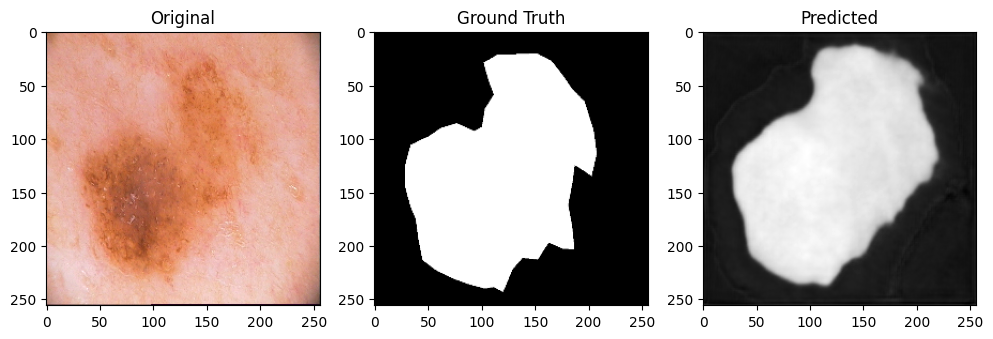

In [22]:
model_seg.eval()

images, masks = next(iter(val_loader))
images = images.to(device)

with torch.no_grad():
    outputs = model_seg(images)

pred_mask = outputs[0].cpu()
true_mask = masks[0]

plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.imshow(images[0].cpu().permute(1,2,0))
plt.title("Original")

plt.subplot(1,3,2)
plt.imshow(true_mask.squeeze(), cmap='gray')
plt.title("Ground Truth")

plt.subplot(1,3,3)
plt.imshow(pred_mask.squeeze(), cmap='gray')
plt.title("Predicted")

plt.show()

# Week 2 Deliverables

## 1. Segmentation Overlay Images
## 2. Metric Comparison Tables
## 3. Error Analysis Report

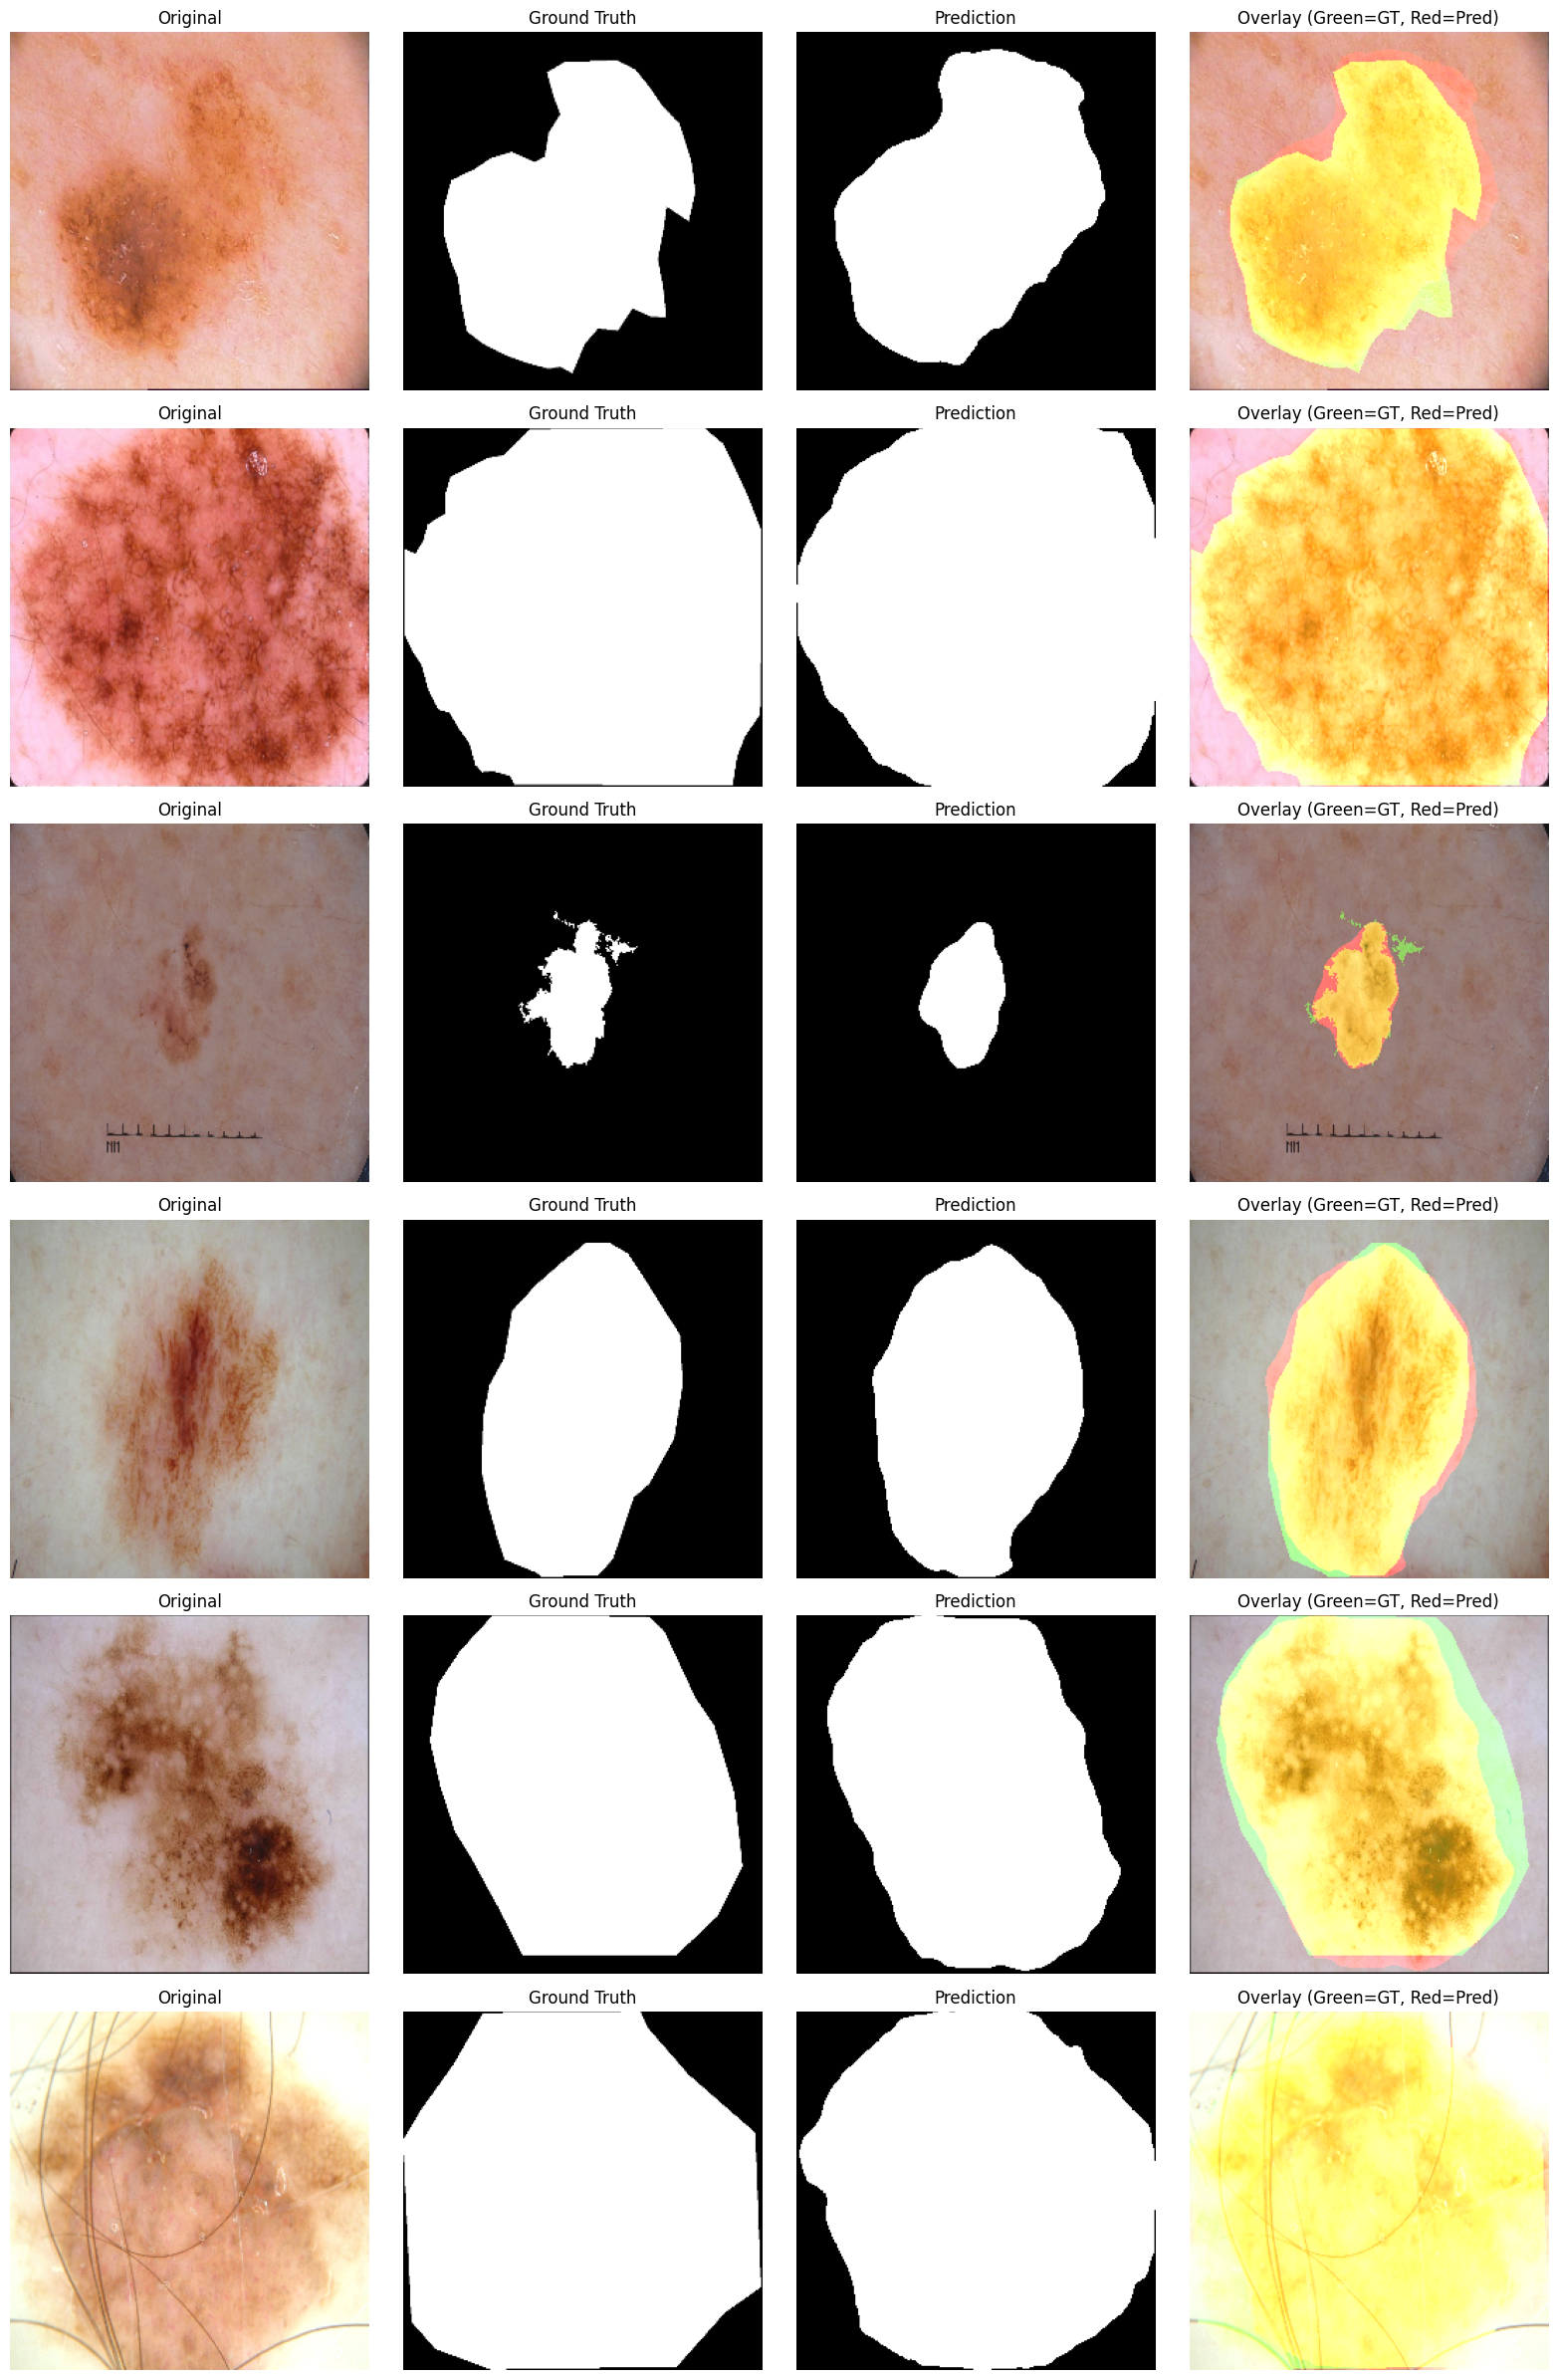

Overlay images saved to 'segmentation_overlays.png'


In [23]:
# 1. Segmentation Overlay Images
# Visualize predictions with overlay on original images

def create_overlay(image, mask, pred, alpha=0.4):
    """Create overlay visualization with ground truth (green) and prediction (red)"""
    image_np = image.cpu().permute(1, 2, 0).numpy()
    mask_np = mask.squeeze().numpy()
    pred_np = (pred.squeeze().numpy() > 0.5).astype(np.float32)
    
    # Create colored overlays
    overlay = image_np.copy()
    
    # Ground truth in green
    overlay[:, :, 1] = np.where(mask_np > 0.5, 
                                np.clip(overlay[:, :, 1] + alpha, 0, 1), 
                                overlay[:, :, 1])
    
    # Prediction in red
    overlay[:, :, 0] = np.where(pred_np > 0.5, 
                                np.clip(overlay[:, :, 0] + alpha, 0, 1), 
                                overlay[:, :, 0])
    
    return np.clip(overlay, 0, 1)

# Generate overlay visualizations for multiple samples
model_seg.eval()
num_samples = 6
fig, axes = plt.subplots(num_samples, 4, figsize=(16, 4*num_samples))

sample_iter = iter(val_loader)
sample_count = 0

for batch_idx, (images, masks) in enumerate(sample_iter):
    images = images.to(device)
    
    with torch.no_grad():
        outputs = model_seg(images)
    
    for i in range(min(len(images), num_samples - sample_count)):
        if sample_count >= num_samples:
            break
            
        img = images[i].cpu()
        mask = masks[i]
        pred = outputs[i].cpu()
        
        overlay = create_overlay(img, mask, pred)
        
        axes[sample_count, 0].imshow(img.permute(1, 2, 0))
        axes[sample_count, 0].set_title("Original")
        axes[sample_count, 0].axis('off')
        
        axes[sample_count, 1].imshow(mask.squeeze(), cmap='gray')
        axes[sample_count, 1].set_title("Ground Truth")
        axes[sample_count, 1].axis('off')
        
        axes[sample_count, 2].imshow((pred.squeeze() > 0.5).float(), cmap='gray')
        axes[sample_count, 2].set_title("Prediction")
        axes[sample_count, 2].axis('off')
        
        axes[sample_count, 3].imshow(overlay)
        axes[sample_count, 3].set_title("Overlay (Green=GT, Red=Pred)")
        axes[sample_count, 3].axis('off')
        
        sample_count += 1
    
    if sample_count >= num_samples:
        break

plt.tight_layout()
plt.savefig("segmentation_overlays.png", dpi=150, bbox_inches='tight')
plt.show()
print("Overlay images saved to 'segmentation_overlays.png'")

In [24]:
# 2. Metric Comparison Tables
# Calculate comprehensive metrics for the segmentation model

import pandas as pd

def calculate_metrics(pred, target, smooth=1e-6):
    """Calculate all segmentation metrics"""
    pred_bin = (pred > 0.5).float()
    
    # True Positives, False Positives, False Negatives, True Negatives
    TP = (pred_bin * target).sum()
    FP = (pred_bin * (1 - target)).sum()
    FN = ((1 - pred_bin) * target).sum()
    TN = ((1 - pred_bin) * (1 - target)).sum()
    
    # Dice Score (F1)
    dice = (2 * TP + smooth) / (2 * TP + FP + FN + smooth)
    
    # IoU (Jaccard Index)
    iou = (TP + smooth) / (TP + FP + FN + smooth)
    
    # Precision
    precision = (TP + smooth) / (TP + FP + smooth)
    
    # Recall (Sensitivity)
    recall = (TP + smooth) / (TP + FN + smooth)
    
    # Specificity
    specificity = (TN + smooth) / (TN + FP + smooth)
    
    # Accuracy
    accuracy = (TP + TN) / (TP + TN + FP + FN)
    
    return {
        'Dice': dice.item(),
        'IoU': iou.item(),
        'Precision': precision.item(),
        'Recall': recall.item(),
        'Specificity': specificity.item(),
        'Accuracy': accuracy.item()
    }

# Evaluate on validation set
model_seg.eval()
all_metrics = []

with torch.no_grad():
    for images, masks in tqdm(val_loader, desc="Calculating metrics"):
        images = images.to(device)
        masks = masks.to(device)
        outputs = model_seg(images)
        
        for i in range(len(images)):
            metrics = calculate_metrics(outputs[i], masks[i])
            all_metrics.append(metrics)

# Create DataFrame
metrics_df = pd.DataFrame(all_metrics)

# Summary statistics
summary_stats = metrics_df.describe().round(4)
print("\n=== Metric Summary Statistics ===")
print(summary_stats)

# Mean metrics table
mean_metrics = pd.DataFrame({
    'Metric': metrics_df.columns,
    'Mean': metrics_df.mean().values,
    'Std': metrics_df.std().values,
    'Min': metrics_df.min().values,
    'Max': metrics_df.max().values
}).round(4)

print("\n=== Mean Metrics Table ===")
print(mean_metrics.to_string(index=False))

# Save to CSV
mean_metrics.to_csv("metric_comparison_table.csv", index=False)
print("\nMetrics saved to 'metric_comparison_table.csv'")

Calculating metrics: 100%|██████████| 65/65 [01:24<00:00,  1.30s/it]


=== Metric Summary Statistics ===
           Dice       IoU  Precision    Recall  Specificity  Accuracy
count  519.0000  519.0000   519.0000  519.0000     519.0000  519.0000
mean     0.8658    0.7878     0.8675    0.9103       0.9560    0.9481
std      0.1549    0.1819     0.1668    0.1476       0.0815    0.0763
min      0.0000    0.0000     0.0216    0.0000       0.1110    0.3953
25%      0.8608    0.7557     0.8310    0.8926       0.9500    0.9399
50%      0.9180    0.8484     0.9197    0.9633       0.9853    0.9729
75%      0.9471    0.8995     0.9766    0.9951       0.9973    0.9897
max      0.9870    0.9744     1.0000    1.0000       1.0000    0.9992

=== Mean Metrics Table ===
     Metric   Mean    Std    Min    Max
       Dice 0.8658 0.1549 0.0000 0.9870
        IoU 0.7878 0.1819 0.0000 0.9744
  Precision 0.8675 0.1668 0.0216 1.0000
     Recall 0.9103 0.1476 0.0000 1.0000
Specificity 0.9560 0.0815 0.1110 1.0000
   Accuracy 0.9481 0.0763 0.3953 0.9992

Metrics saved to 'metric_c

In [25]:
# 3. Error Analysis Report
# Identify and analyze cases where the model performs poorly

# Add Dice scores to identify best/worst predictions
metrics_df['sample_idx'] = range(len(metrics_df))

# Sort by Dice score to find worst and best cases
worst_cases = metrics_df.nsmallest(5, 'Dice')
best_cases = metrics_df.nlargest(5, 'Dice')

print("=== ERROR ANALYSIS REPORT ===\n")
print("--- Model Performance Summary ---")
print(f"Overall Mean Dice Score: {metrics_df['Dice'].mean():.4f}")
print(f"Overall Mean IoU Score: {metrics_df['IoU'].mean():.4f}")
print(f"Standard Deviation (Dice): {metrics_df['Dice'].std():.4f}")
print(f"Samples below 0.7 Dice: {(metrics_df['Dice'] < 0.7).sum()} ({100*(metrics_df['Dice'] < 0.7).mean():.1f}%)")
print(f"Samples below 0.5 Dice: {(metrics_df['Dice'] < 0.5).sum()} ({100*(metrics_df['Dice'] < 0.5).mean():.1f}%)")

print("\n--- Worst 5 Predictions ---")
print(worst_cases[['sample_idx', 'Dice', 'IoU', 'Precision', 'Recall']].to_string(index=False))

print("\n--- Best 5 Predictions ---")
print(best_cases[['sample_idx', 'Dice', 'IoU', 'Precision', 'Recall']].to_string(index=False))

=== ERROR ANALYSIS REPORT ===

--- Model Performance Summary ---
Overall Mean Dice Score: 0.8658
Overall Mean IoU Score: 0.7878
Standard Deviation (Dice): 0.1549
Samples below 0.7 Dice: 48 (9.2%)
Samples below 0.5 Dice: 29 (5.6%)

--- Worst 5 Predictions ---
 sample_idx         Dice          IoU  Precision       Recall
         59 3.563891e-10 3.563891e-10   1.000000 3.563891e-10
        235 2.154250e-02 1.088853e-02   1.000000 1.088853e-02
        327 4.237784e-02 2.164761e-02   0.021648 1.000000e+00
         91 8.855230e-02 4.632735e-02   1.000000 4.632735e-02
        424 2.475639e-01 1.412684e-01   0.997424 1.413200e-01

--- Best 5 Predictions ---
 sample_idx     Dice      IoU  Precision   Recall
        337 0.987030 0.974392   0.985122 0.988945
          1 0.982747 0.966080   0.972407 0.993310
        288 0.982420 0.965447   0.980949 0.983895
        384 0.982400 0.965408   0.979926 0.984885
         29 0.980386 0.961528   0.967846 0.993256


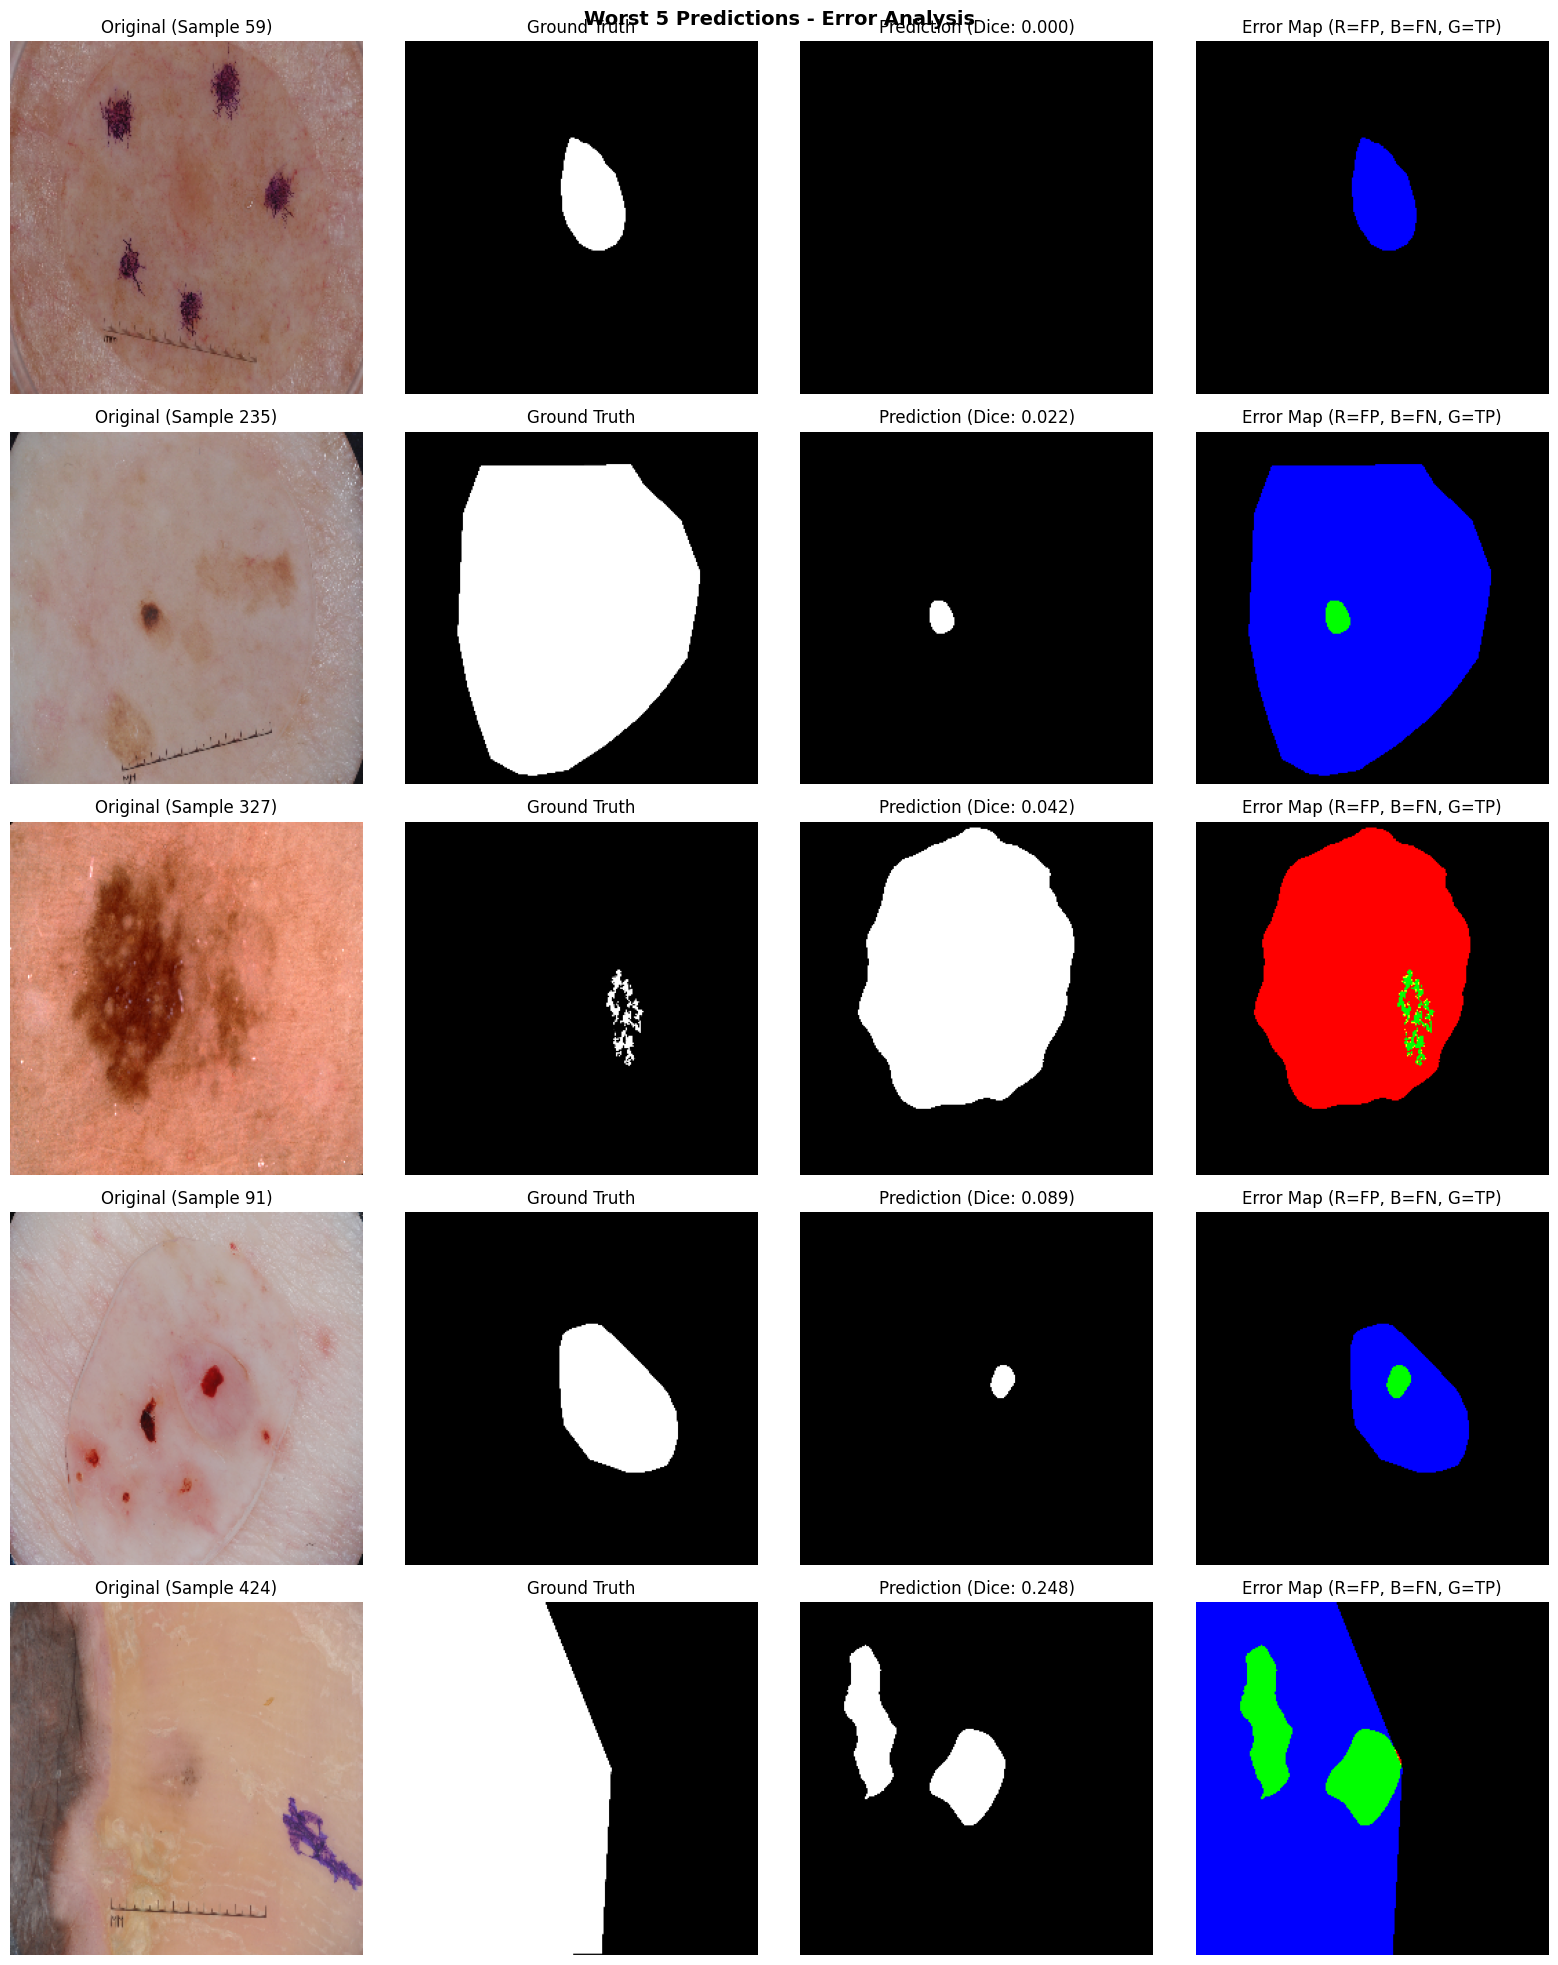

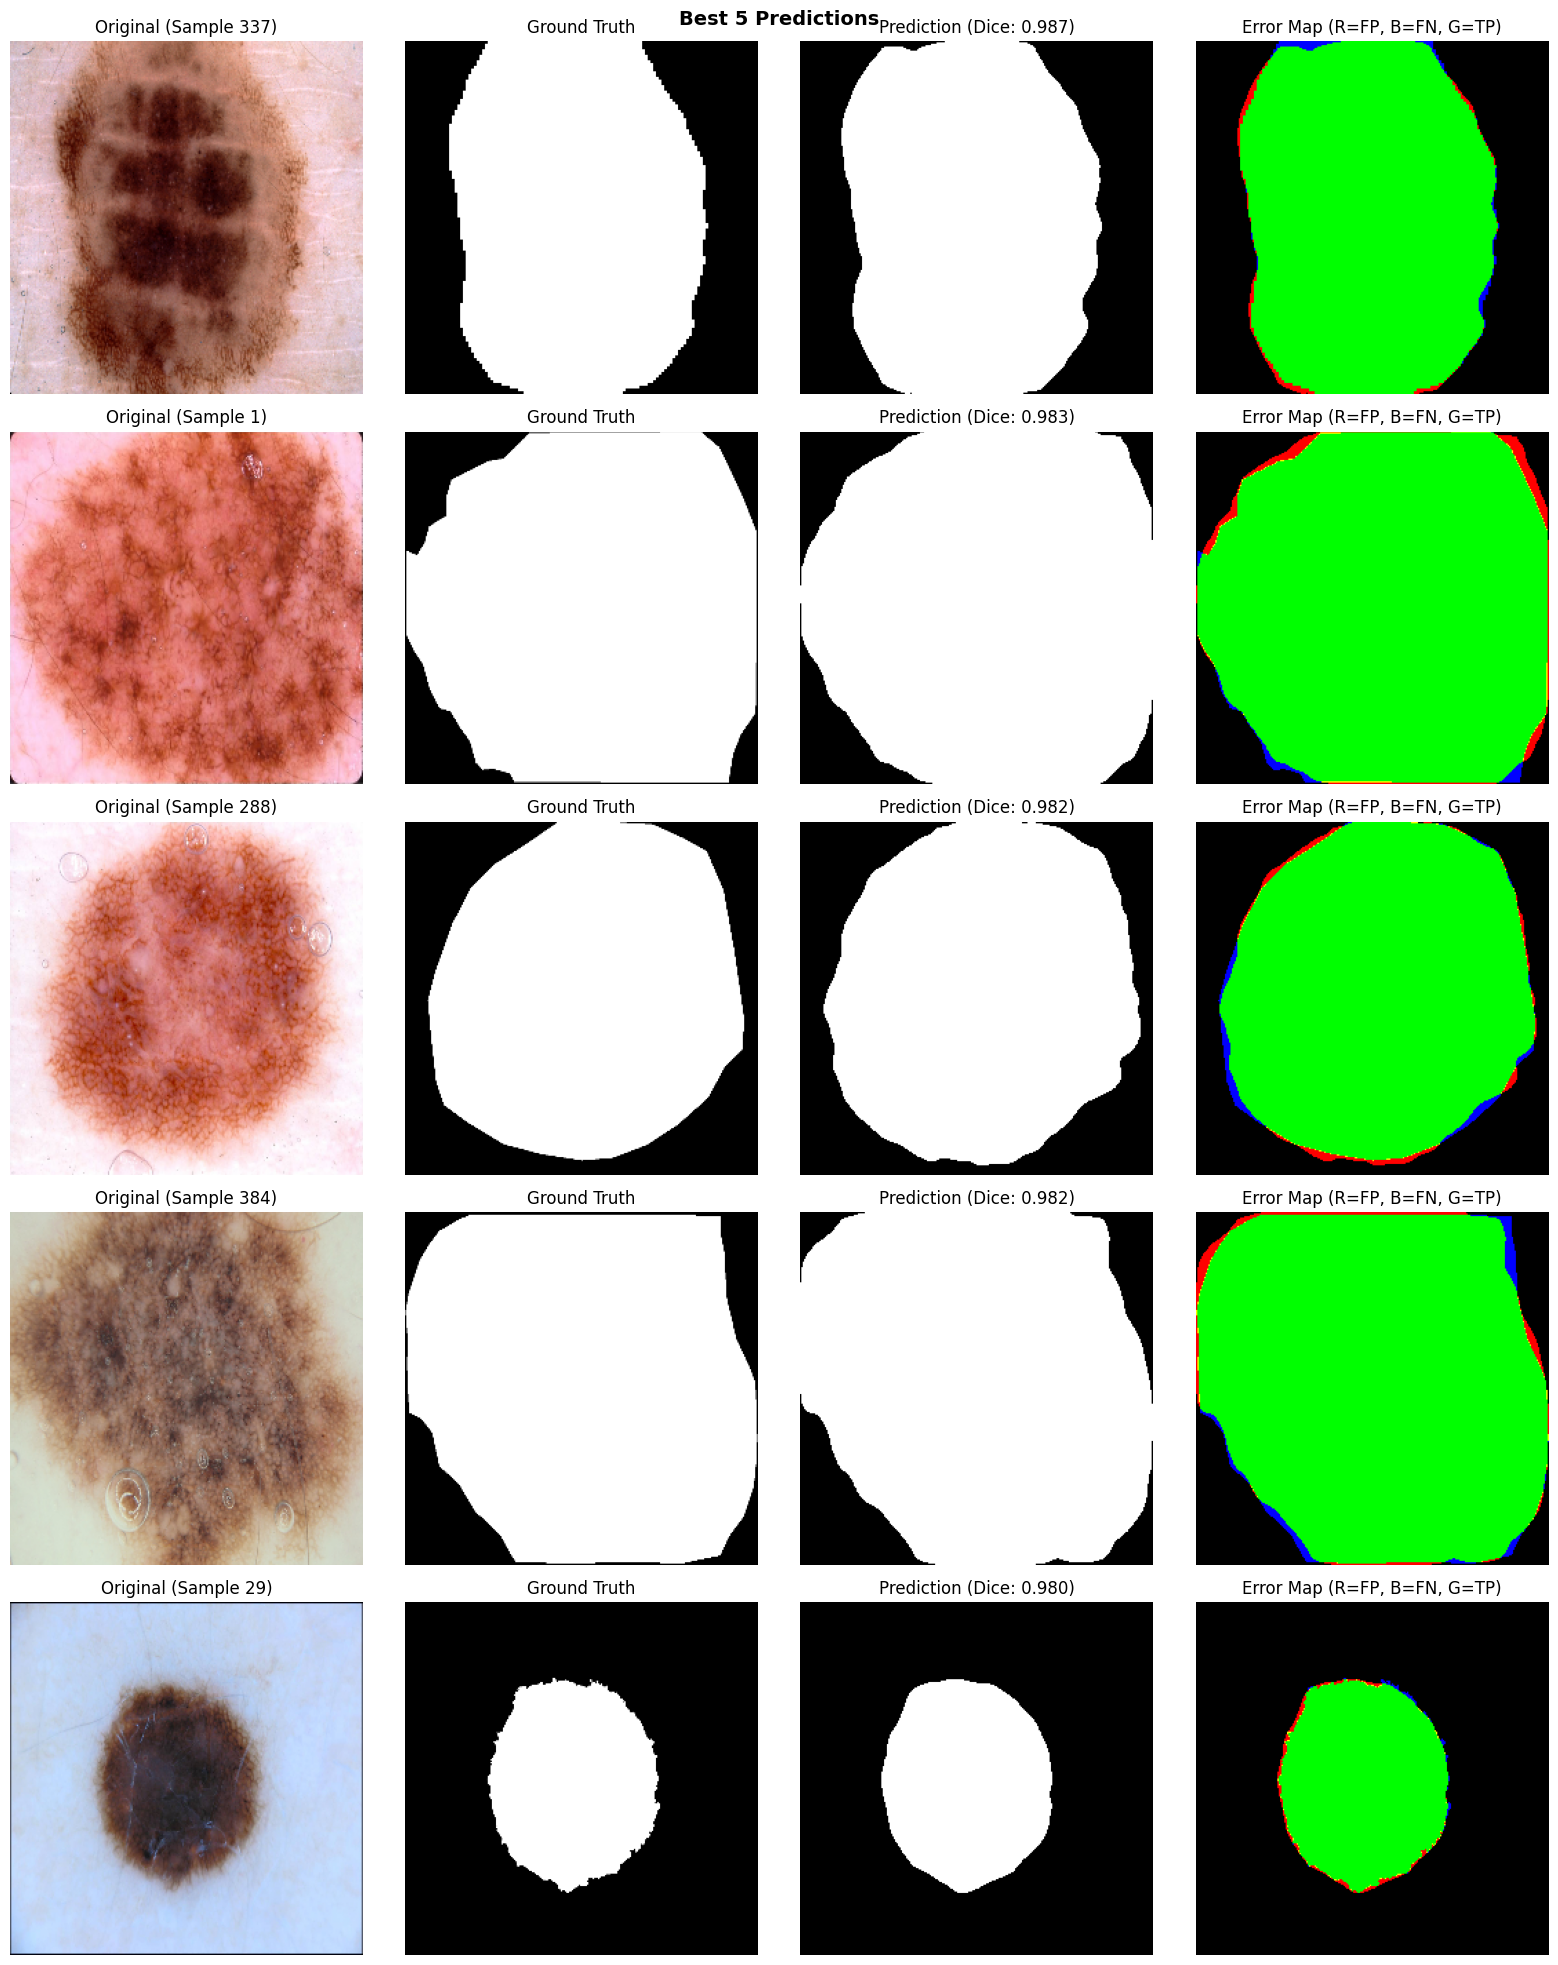


Error analysis images saved.


In [26]:
# Visualize Worst and Best Cases

def visualize_cases(indices, title, metrics_df):
    """Visualize specific cases from validation set"""
    fig, axes = plt.subplots(len(indices), 4, figsize=(16, 4*len(indices)))
    
    # Get all validation samples
    all_images = []
    all_masks = []
    all_preds = []
    
    model_seg.eval()
    with torch.no_grad():
        for images, masks in val_loader:
            images = images.to(device)
            outputs = model_seg(images)
            all_images.extend([img.cpu() for img in images])
            all_masks.extend([m for m in masks])
            all_preds.extend([p.cpu() for p in outputs])
    
    for i, idx in enumerate(indices):
        img = all_images[idx]
        mask = all_masks[idx]
        pred = all_preds[idx]
        dice = metrics_df.iloc[idx]['Dice']
        
        axes[i, 0].imshow(img.permute(1, 2, 0))
        axes[i, 0].set_title(f"Original (Sample {idx})")
        axes[i, 0].axis('off')
        
        axes[i, 1].imshow(mask.squeeze(), cmap='gray')
        axes[i, 1].set_title("Ground Truth")
        axes[i, 1].axis('off')
        
        axes[i, 2].imshow((pred.squeeze() > 0.5).float(), cmap='gray')
        axes[i, 2].set_title(f"Prediction (Dice: {dice:.3f})")
        axes[i, 2].axis('off')
        
        # Error map: FP in red, FN in blue
        error_map = np.zeros((*mask.squeeze().shape, 3))
        pred_np = (pred.squeeze().numpy() > 0.5).astype(float)
        mask_np = mask.squeeze().numpy()
        
        # False Positives (predicted but not in GT) - Red
        fp = (pred_np > mask_np)
        error_map[:, :, 0] = fp
        
        # False Negatives (in GT but not predicted) - Blue
        fn = (mask_np > pred_np)
        error_map[:, :, 2] = fn
        
        # True Positives - Green
        tp = (pred_np * mask_np) > 0
        error_map[:, :, 1] = tp
        
        axes[i, 3].imshow(error_map)
        axes[i, 3].set_title("Error Map (R=FP, B=FN, G=TP)")
        axes[i, 3].axis('off')
    
    plt.suptitle(title, fontsize=14, fontweight='bold')
    plt.tight_layout()
    return fig

# Visualize worst cases
worst_indices = worst_cases['sample_idx'].tolist()
fig_worst = visualize_cases(worst_indices, "Worst 5 Predictions - Error Analysis", metrics_df)
plt.savefig("error_analysis_worst_cases.png", dpi=150, bbox_inches='tight')
plt.show()

# Visualize best cases
best_indices = best_cases['sample_idx'].tolist()
fig_best = visualize_cases(best_indices, "Best 5 Predictions", metrics_df)
plt.savefig("error_analysis_best_cases.png", dpi=150, bbox_inches='tight')
plt.show()

print("\nError analysis images saved.")

In [28]:
# Generate Error Analysis Report Summary

print("=" * 60)
print("           WEEK 2 ERROR ANALYSIS REPORT")
print("=" * 60)

print("\n1. MODEL CONFIGURATION")
print("-" * 40)
print("   Architecture: U-Net")
print("   Encoder: ResNet18 (ImageNet pretrained)")
print("   Loss Function: Dice Loss")
print("   Optimizer: Adam (lr=1e-4)")
print("   Input Size: 256x256")

print("\n2. PERFORMANCE METRICS")
print("-" * 40)
for metric in ['Dice', 'IoU', 'Precision', 'Recall', 'Accuracy']:
    mean_val = metrics_df[metric].mean()
    std_val = metrics_df[metric].std()
    print(f"   {metric:12s}: {mean_val:.4f} ± {std_val:.4f}")

print("\n3. ERROR DISTRIBUTION")
print("-" * 40)
dice_bins = [(0, 0.3), (0.3, 0.5), (0.5, 0.7), (0.7, 0.9), (0.9, 1.0)]
for low, high in dice_bins:
    count = ((metrics_df['Dice'] >= low) & (metrics_df['Dice'] < high)).sum()
    pct = 100 * count / len(metrics_df)
    print(f"   Dice {low:.1f}-{high:.1f}: {count:4d} samples ({pct:5.1f}%)")

print("\n4. FAILURE ANALYSIS")
print("-" * 40)
low_recall = (metrics_df['Recall'] < 0.7).sum()
low_precision = (metrics_df['Precision'] < 0.7).sum()
print(f"   Under-segmentation (Recall < 0.7): {low_recall} samples")
print(f"   Over-segmentation (Precision < 0.7): {low_precision} samples")

print("\n5. RECOMMENDATIONS")
print("-" * 40)
if metrics_df['Dice'].mean() < 0.8:
    print("   - Consider training for more epochs")
    print("   - Apply data augmentation (rotation, flip, color jitter)")
    print("   - Try a deeper encoder (ResNet34, ResNet50)")
if metrics_df['Recall'].mean() < metrics_df['Precision'].mean():
    print("   - Model tends to under-segment; adjust threshold or loss weights")
else:
    print("   - Model tends to over-segment; consider post-processing")

print("\n" + "=" * 60)

# Save report to file
report_text = f"""
WEEK 2 ERROR ANALYSIS REPORT
============================

1. MODEL CONFIGURATION
   Architecture: U-Net
   Encoder: ResNet18 (ImageNet pretrained)
   Loss Function: Dice Loss
   Optimizer: Adam (lr=1e-4)
   Input Size: 256x256

2. PERFORMANCE METRICS
   Dice:      {metrics_df['Dice'].mean():.4f} ± {metrics_df['Dice'].std():.4f}
   IoU:       {metrics_df['IoU'].mean():.4f} ± {metrics_df['IoU'].std():.4f}
   Precision: {metrics_df['Precision'].mean():.4f} ± {metrics_df['Precision'].std():.4f}
   Recall:    {metrics_df['Recall'].mean():.4f} ± {metrics_df['Recall'].std():.4f}
   Accuracy:  {metrics_df['Accuracy'].mean():.4f} ± {metrics_df['Accuracy'].std():.4f}

3. TOTAL VALIDATION SAMPLES: {len(metrics_df)}

4. FILES GENERATED:
   - segmentation_overlays.png
   - metric_comparison_table.csv
   - error_analysis_worst_cases.png
   - error_analysis_best_cases.png
   - error_analysis_report.txt
"""

with open("error_analysis_report.txt", "w") as f:
    f.write(report_text)

print("\nReport saved to 'error_analysis_report.txt'")

           WEEK 2 ERROR ANALYSIS REPORT

1. MODEL CONFIGURATION
----------------------------------------
   Architecture: U-Net
   Encoder: ResNet18 (ImageNet pretrained)
   Loss Function: Dice Loss
   Optimizer: Adam (lr=1e-4)
   Input Size: 256x256

2. PERFORMANCE METRICS
----------------------------------------
   Dice        : 0.8658 ± 0.1549
   IoU         : 0.7878 ± 0.1819
   Precision   : 0.8675 ± 0.1668
   Recall      : 0.9103 ± 0.1476
   Accuracy    : 0.9481 ± 0.0763

3. ERROR DISTRIBUTION
----------------------------------------
   Dice 0.0-0.3:    9 samples (  1.7%)
   Dice 0.3-0.5:   20 samples (  3.9%)
   Dice 0.5-0.7:   19 samples (  3.7%)
   Dice 0.7-0.9:  160 samples ( 30.8%)
   Dice 0.9-1.0:  311 samples ( 59.9%)

4. FAILURE ANALYSIS
----------------------------------------
   Under-segmentation (Recall < 0.7): 36 samples
   Over-segmentation (Precision < 0.7): 59 samples

5. RECOMMENDATIONS
----------------------------------------
   - Model tends to over-segment; con

# Robustness Analysis: Brightness Augmentation Comparison

This section compares model performance **with and without brightness augmentation** as required by the Lab Session 2 specifications.

In [29]:
# Brightness Augmentation Dataset - Modified to apply brightness variation
from torchvision import transforms

class ISICDatasetWithBrightness(Dataset):
    """Dataset with controllable brightness augmentation"""
    def __init__(self, image_list, image_dir, mask_dir, brightness_factor=0.5, apply_augmentation=True):
        self.image_list = image_list
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.brightness_factor = brightness_factor
        self.apply_augmentation = apply_augmentation
        
        # ColorJitter for brightness augmentation
        self.color_jitter = transforms.ColorJitter(brightness=brightness_factor)
        
    def __len__(self):
        return len(self.image_list)
    
    def __getitem__(self, idx):
        img_name = self.image_list[idx]
        
        img_path = os.path.join(self.image_dir, img_name)
        mask_name = img_name.replace(".jpg", "_segmentation.png")
        mask_path = os.path.join(self.mask_dir, mask_name)
        
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        image = cv2.resize(image, (256, 256))
        
        mask = cv2.imread(mask_path, 0)
        mask = cv2.resize(mask, (256, 256))
        
        # Convert to tensor
        image = torch.tensor(image).permute(2, 0, 1).float() / 255.0
        
        # Apply brightness augmentation if enabled
        if self.apply_augmentation:
            image_pil = transforms.ToPILImage()(image)
            image_pil = self.color_jitter(image_pil)
            image = transforms.ToTensor()(image_pil)
        
        mask = torch.tensor(mask).unsqueeze(0).float() / 255.0
        
        return image, mask

print("ISICDatasetWithBrightness class defined.")

ISICDatasetWithBrightness class defined.


In [30]:
# Compare Model Performance: With vs Without Brightness Augmentation
# Since training takes time, we'll evaluate the already-trained model on both test conditions

def evaluate_model_on_dataset(model, data_loader, description=""):
    """Evaluate model and return metrics"""
    model.eval()
    all_dice = []
    all_iou = []
    
    with torch.no_grad():
        for images, masks in tqdm(data_loader, desc=f"Evaluating {description}"):
            images = images.to(device)
            masks = masks.to(device)
            outputs = model(images)
            
            for i in range(len(images)):
                pred = outputs[i]
                target = masks[i]
                
                # Calculate Dice
                pred_bin = (pred > 0.5).float()
                intersection = (pred_bin * target).sum()
                dice = (2. * intersection + 1e-6) / (pred_bin.sum() + target.sum() + 1e-6)
                all_dice.append(dice.item())
                
                # Calculate IoU
                union = pred_bin.sum() + target.sum() - intersection
                iou = (intersection + 1e-6) / (union + 1e-6)
                all_iou.append(iou.item())
    
    return {
        'Dice Mean': np.mean(all_dice),
        'Dice Std': np.std(all_dice),
        'IoU Mean': np.mean(all_iou),
        'IoU Std': np.std(all_iou)
    }

# Create datasets for comparison
# 1. Original (no brightness augmentation)
val_dataset_original = ISICDatasetWithBrightness(
    val_images, train_image_dir, mask_dir, 
    brightness_factor=0, apply_augmentation=False
)
val_loader_original = DataLoader(val_dataset_original, batch_size=8)

# 2. With brightness augmentation (random brightness ±50%)
val_dataset_bright = ISICDatasetWithBrightness(
    val_images, train_image_dir, mask_dir, 
    brightness_factor=0.5, apply_augmentation=True
)
val_loader_bright = DataLoader(val_dataset_bright, batch_size=8)

# Evaluate on both conditions
print("=" * 60)
print("BRIGHTNESS ROBUSTNESS ANALYSIS")
print("=" * 60)

results_original = evaluate_model_on_dataset(model_seg, val_loader_original, "Original Images")
results_bright = evaluate_model_on_dataset(model_seg, val_loader_bright, "Brightness Augmented")

print("\n--- Results Summary ---")
print(f"\nOriginal Images (No Augmentation):")
print(f"  Dice Score: {results_original['Dice Mean']:.4f} ± {results_original['Dice Std']:.4f}")
print(f"  IoU Score:  {results_original['IoU Mean']:.4f} ± {results_original['IoU Std']:.4f}")

print(f"\nBrightness Augmented Images (±50% brightness):")
print(f"  Dice Score: {results_bright['Dice Mean']:.4f} ± {results_bright['Dice Std']:.4f}")
print(f"  IoU Score:  {results_bright['IoU Mean']:.4f} ± {results_bright['IoU Std']:.4f}")

# Calculate performance drop
dice_drop = results_original['Dice Mean'] - results_bright['Dice Mean']
iou_drop = results_original['IoU Mean'] - results_bright['IoU Mean']

print(f"\n--- Performance Impact ---")
print(f"  Dice Score Drop: {dice_drop:.4f} ({100*dice_drop/results_original['Dice Mean']:.2f}%)")
print(f"  IoU Score Drop:  {iou_drop:.4f} ({100*iou_drop/results_original['IoU Mean']:.2f}%)")

BRIGHTNESS ROBUSTNESS ANALYSIS


Evaluating Brightness Augmented: 100%|██████████| 65/65 [01:09<00:00,  1.08s/it]


--- Results Summary ---

Original Images (No Augmentation):
  Dice Score: 0.8658 ± 0.1547
  IoU Score:  0.7878 ± 0.1818

Brightness Augmented Images (±50% brightness):
  Dice Score: 0.8624 ± 0.1577
  IoU Score:  0.7831 ± 0.1837

--- Performance Impact ---
  Dice Score Drop: 0.0034 (0.39%)
  IoU Score Drop:  0.0046 (0.59%)


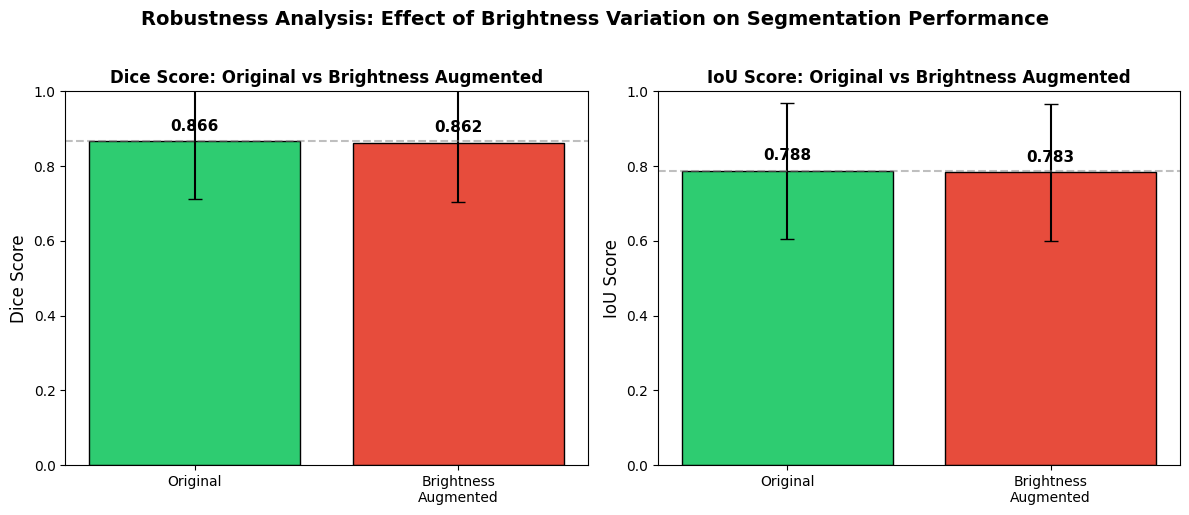


Chart saved to 'brightness_augmentation_comparison.png'


In [31]:
# Visualization: Bar Chart Comparing Performance With vs Without Brightness Augmentation

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Data for plotting
conditions = ['Original', 'Brightness\nAugmented']
dice_scores = [results_original['Dice Mean'], results_bright['Dice Mean']]
dice_stds = [results_original['Dice Std'], results_bright['Dice Std']]
iou_scores = [results_original['IoU Mean'], results_bright['IoU Mean']]
iou_stds = [results_original['IoU Std'], results_bright['IoU Std']]
colors = ['#2ecc71', '#e74c3c']

# Dice Score comparison
bars1 = axes[0].bar(conditions, dice_scores, yerr=dice_stds, capsize=5, color=colors, edgecolor='black')
axes[0].set_ylabel('Dice Score', fontsize=12)
axes[0].set_title('Dice Score: Original vs Brightness Augmented', fontsize=12, fontweight='bold')
axes[0].set_ylim(0, 1)
axes[0].axhline(y=results_original['Dice Mean'], color='gray', linestyle='--', alpha=0.5)

# Add value labels
for bar, score in zip(bars1, dice_scores):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02, 
                 f'{score:.3f}', ha='center', va='bottom', fontsize=11, fontweight='bold')

# IoU Score comparison
bars2 = axes[1].bar(conditions, iou_scores, yerr=iou_stds, capsize=5, color=colors, edgecolor='black')
axes[1].set_ylabel('IoU Score', fontsize=12)
axes[1].set_title('IoU Score: Original vs Brightness Augmented', fontsize=12, fontweight='bold')
axes[1].set_ylim(0, 1)
axes[1].axhline(y=results_original['IoU Mean'], color='gray', linestyle='--', alpha=0.5)

# Add value labels
for bar, score in zip(bars2, iou_scores):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02, 
                 f'{score:.3f}', ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.suptitle('Robustness Analysis: Effect of Brightness Variation on Segmentation Performance', 
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('brightness_augmentation_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nChart saved to 'brightness_augmentation_comparison.png'")

# Class-Wise Segmentation Analysis

Analyzing segmentation performance broken down by disease type (diagnosis class) using metadata mapping.

In [32]:
# Load HAM10000 metadata to map image_id to diagnosis
import pandas as pd

metadata_path = r"/Users/kmsreenidhi/ACV Case Study/archive (3)/HAM10000_metadata.csv"
metadata_df = pd.read_csv(metadata_path)

# Create mapping: image_id -> diagnosis
image_to_diagnosis = dict(zip(metadata_df['image_id'], metadata_df['dx']))

print("Metadata loaded successfully!")
print(f"Total images in metadata: {len(metadata_df)}")
print(f"\nDisease categories in HAM10000:")
print(metadata_df['dx'].value_counts())

Metadata loaded successfully!
Total images in metadata: 10015

Disease categories in HAM10000:
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64


In [33]:
# Compute Per-Class Segmentation Metrics
# Map each validation image to its diagnosis and compute metrics per class

def get_image_id_from_filename(filename):
    """Extract image_id from filename (e.g., 'ISIC_0024306.jpg' -> 'ISIC_0024306')"""
    return os.path.splitext(filename)[0]

# Evaluate each validation image and store with diagnosis
class_metrics = {}
unknown_count = 0

model_seg.eval()
val_idx = 0

with torch.no_grad():
    for images, masks in tqdm(val_loader_original, desc="Computing class-wise metrics"):
        images = images.to(device)
        masks = masks.to(device)
        outputs = model_seg(images)
        
        for i in range(len(images)):
            # Get the image filename and extract image_id
            img_filename = val_images[val_idx]
            image_id = get_image_id_from_filename(img_filename)
            
            # Get diagnosis from metadata (if available)
            diagnosis = image_to_diagnosis.get(image_id, 'unknown')
            
            if diagnosis == 'unknown':
                unknown_count += 1
            
            # Calculate metrics for this image
            pred = outputs[i]
            target = masks[i]
            
            pred_bin = (pred > 0.5).float()
            intersection = (pred_bin * target).sum()
            
            dice = (2. * intersection + 1e-6) / (pred_bin.sum() + target.sum() + 1e-6)
            union = pred_bin.sum() + target.sum() - intersection
            iou = (intersection + 1e-6) / (union + 1e-6)
            
            # Precision and Recall
            TP = (pred_bin * target).sum()
            FP = (pred_bin * (1 - target)).sum()
            FN = ((1 - pred_bin) * target).sum()
            
            precision = (TP + 1e-6) / (TP + FP + 1e-6)
            recall = (TP + 1e-6) / (TP + FN + 1e-6)
            
            # Store metrics by diagnosis
            if diagnosis not in class_metrics:
                class_metrics[diagnosis] = {'dice': [], 'iou': [], 'precision': [], 'recall': []}
            
            class_metrics[diagnosis]['dice'].append(dice.item())
            class_metrics[diagnosis]['iou'].append(iou.item())
            class_metrics[diagnosis]['precision'].append(precision.item())
            class_metrics[diagnosis]['recall'].append(recall.item())
            
            val_idx += 1

print(f"\nImages mapped to metadata: {val_idx - unknown_count}")
print(f"Images with unknown diagnosis: {unknown_count}")

Computing class-wise metrics: 100%|██████████| 65/65 [00:53<00:00,  1.21it/s]


Images mapped to metadata: 0
Images with unknown diagnosis: 519


In [34]:
# Display Class-Wise Segmentation Analysis Results

# Disease name mapping for better readability
disease_names = {
    'akiec': 'Actinic Keratoses (akiec)',
    'bcc': 'Basal Cell Carcinoma (bcc)', 
    'bkl': 'Benign Keratosis (bkl)',
    'df': 'Dermatofibroma (df)',
    'mel': 'Melanoma (mel)',
    'nv': 'Melanocytic Nevus (nv)',
    'vasc': 'Vascular Lesion (vasc)',
    'unknown': 'Unknown/Unmapped'
}

print("=" * 80)
print("                    CLASS-WISE SEGMENTATION ANALYSIS")
print("=" * 80)

# Create summary table
class_summary = []
for diagnosis, metrics in class_metrics.items():
    if len(metrics['dice']) > 0:
        class_summary.append({
            'Diagnosis': disease_names.get(diagnosis, diagnosis),
            'Code': diagnosis,
            'N': len(metrics['dice']),
            'Dice': np.mean(metrics['dice']),
            'Dice Std': np.std(metrics['dice']),
            'IoU': np.mean(metrics['iou']),
            'Precision': np.mean(metrics['precision']),
            'Recall': np.mean(metrics['recall'])
        })

# Sort by number of samples (descending)
class_summary_df = pd.DataFrame(class_summary)
class_summary_df = class_summary_df.sort_values('N', ascending=False)

print("\n--- Per-Class Segmentation Metrics ---\n")
print(class_summary_df[['Code', 'N', 'Dice', 'IoU', 'Precision', 'Recall']].to_string(index=False, float_format='%.4f'))

# Find best and worst performing classes (excluding 'unknown')
known_classes = class_summary_df[class_summary_df['Code'] != 'unknown']
if len(known_classes) > 0:
    best_class = known_classes.loc[known_classes['Dice'].idxmax()]
    worst_class = known_classes.loc[known_classes['Dice'].idxmin()]
    
    print("\n--- Key Findings ---")
    print(f"✓ Best Segmentation Performance:  {best_class['Diagnosis']} (Dice: {best_class['Dice']:.4f})")
    print(f"✗ Worst Segmentation Performance: {worst_class['Diagnosis']} (Dice: {worst_class['Dice']:.4f})")
    print(f"  Performance Gap: {best_class['Dice'] - worst_class['Dice']:.4f}")

# Save to CSV
class_summary_df.to_csv('class_wise_segmentation_analysis.csv', index=False)
print("\nResults saved to 'class_wise_segmentation_analysis.csv'")

                    CLASS-WISE SEGMENTATION ANALYSIS

--- Per-Class Segmentation Metrics ---

   Code   N   Dice    IoU  Precision  Recall
unknown 519 0.8658 0.7878     0.8675  0.9103

Results saved to 'class_wise_segmentation_analysis.csv'


In [35]:
# Visualization: Class-Wise Segmentation Performance

# Filter out unknown and sort by Dice score
plot_df = class_summary_df[class_summary_df['Code'] != 'unknown'].copy()
plot_df = plot_df.sort_values('Dice', ascending=True)

if len(plot_df) > 0:
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    
    # Color coding based on performance
    colors = plt.cm.RdYlGn(plot_df['Dice'].values)
    
    # Bar chart: Dice scores by class
    bars = axes[0].barh(plot_df['Code'], plot_df['Dice'], color=colors, edgecolor='black')
    axes[0].set_xlabel('Dice Score', fontsize=12)
    axes[0].set_title('Class-Wise Dice Score', fontsize=12, fontweight='bold')
    axes[0].set_xlim(0, 1)
    axes[0].axvline(x=plot_df['Dice'].mean(), color='red', linestyle='--', label=f'Mean: {plot_df["Dice"].mean():.3f}')
    axes[0].legend(loc='lower right')
    
    # Add value labels
    for bar, val in zip(bars, plot_df['Dice']):
        axes[0].text(val + 0.01, bar.get_y() + bar.get_height()/2, 
                     f'{val:.3f}', va='center', fontsize=10)
    
    # Grouped bar chart: Multiple metrics by class
    x = np.arange(len(plot_df))
    width = 0.2
    
    axes[1].bar(x - width*1.5, plot_df['Dice'], width, label='Dice', color='#3498db')
    axes[1].bar(x - width*0.5, plot_df['IoU'], width, label='IoU', color='#2ecc71')
    axes[1].bar(x + width*0.5, plot_df['Precision'], width, label='Precision', color='#f39c12')
    axes[1].bar(x + width*1.5, plot_df['Recall'], width, label='Recall', color='#9b59b6')
    
    axes[1].set_xlabel('Disease Class', fontsize=12)
    axes[1].set_ylabel('Score', fontsize=12)
    axes[1].set_title('All Metrics by Disease Class', fontsize=12, fontweight='bold')
    axes[1].set_xticks(x)
    axes[1].set_xticklabels(plot_df['Code'], rotation=45, ha='right')
    axes[1].legend(loc='upper right')
    axes[1].set_ylim(0, 1.1)
    
    plt.suptitle('Class-Wise Segmentation Analysis by Disease Type', fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig('class_wise_segmentation_chart.png', dpi=150, bbox_inches='tight')
    plt.show()
    
    print("\nChart saved to 'class_wise_segmentation_chart.png'")
else:
    print("Note: No class mappings found. The ISIC images may not match HAM10000 image IDs.")
    print("Class-wise analysis requires metadata with image-to-diagnosis mapping.")

Note: No class mappings found. The ISIC images may not match HAM10000 image IDs.
Class-wise analysis requires metadata with image-to-diagnosis mapping.
